Implementation of MOE from Scratch



In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


In [ ]:
##an expert can be nothing but a feed forward network
#adding feed forward networ with 2 linear layer
# it will get input in in_dim and shrink to hiddem dimension hidden_dim
# and then expand back to input dimensions
# dring this staage it is gonna chnege the weights of input tokens

structure of expert


In [13]:
class Expert(nn.Module):
  def __init__(self,in_dim,hidden_dim):
    super().__init__()
    self.ffl1=nn.Linear(in_dim,hidden_dim)
    self.ffl2=nn.Linear(hidden_dim,in_dim)

  #forward pass

  def forward(self,x):
    out1=self.ffl1(x)

    # input token goes to first layyer
    #and then goes to 2nd layer but as it goes it goe through
    #intermediate activation or intermediate non linear func
    out2=self.ffl2(F.silu(out1))

    return out2


In [14]:
#moe
# we have collections of experts

# num experts tellshow  many experts are there  in language model
# top k - how man experts to select at a pt of time

# router it is gonna tell the  probabilty of a  particluar token for being routed to experts
# once we have probabilty
# we seletct top k experts

import matplotlib.pyplot as plt
import numpy as np

def visualize_matrix(
    matrix,
    title="Matrix Visualization",
    x_label="Columns",
    y_label="Rows",
    width=8
):
    matrix = matrix.detach().cpu().numpy()

    plt.figure(figsize=(width, 6))
    plt.imshow(matrix, cmap="viridis", aspect="auto")
    plt.colorbar()
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.tight_layout()
    plt.show()

class MOELayer(nn.Module):
  #mixtuure of experts layer

  def __init__(self,in_dim,hidden_dim,num_experts,top_k=2):

    super().__init__()

    self.num_experts=num_experts
    self.top_k=top_k

    self.router=nn.Linear(in_dim,num_experts,bias=False)


    self.experts=nn.ModuleList(
        [Expert(in_dim,hidden_dim) for _ in range(self.num_experts)]
    )

  def forward(self,x):
    # forward pass = > input is 3 dimensional tensors
    batch_size,seq_len,d_model=x.shape

    print(
        f'Batch size : {batch_size}\n',
        f'Sequence length : {seq_len}\n',
        f'Embedding dimensions : {d_model}\n',
    )
    x_flat=x.view(-1,d_model)#flatteng coversion of 3d to 2dd
    print(
        f'Flatten Dimensions : {x_flat.shape}\n',
    )
    # send to router and convert thrm to probabity dist through softmax
    router_logits=self.router(x_flat)
    routing_probs=F.softmax(router_logits,dim=1)
    print(
        f'Router Output Shape : {routing_probs.shape}\n'
    )
    visualize_matrix(routing_probs,x_label='Router Probabilites for Experts',y_label='Tokens'
    )


    top_k_probs,top_k_indices=torch.topk(routing_probs,self.top_k,dim=-1)
    top_k_probs=top_k_probs/top_k_probs.sum(dim=-1,keepdim=True)
#we are normalizin fby divideing sum prob of row

    visualize_matrix(
        top_k_probs,
        x_label=f'Router Probabilites for top {self.top_k} Experts',
        y_label='Tokens'
    )
    visualize_matrix(
        top_k_indices,
        x_label=f'expert indices for top {self.top_k} Experts',
        y_label='Tokens'
    )


    final_output=torch.zeros_like(x_flat)

    for i,expert in enumerate(self.experts):
      #fwd loop that loop through all experts
      print(f'current expert index: {i}')
      expert_mask=(top_k_indices==i)

      #at a particular time what are the token to which a particular expert attending to
      visualize_matrix(
        expert_mask,
        x_label=f'Expert mask',
        y_label='Tokens'
    )
      token_indices=expert_mask.any(dim=-1)
      print(token_indices)
      #if it is not continuedig the expert we contiue

      if not token_indices.any():
        print('Skipping the Expert,since it has no tokens to attend')
        continue

        #if it is attending to some experts
      token_for_expert=x_flat[token_indices]
      visualize_matrix(
        token_for_expert,
        x_label=f'Embedding dimensions',
        y_label='selected tokens for expert to attend',
        width=15,
        )
      expert_output=expert(token_for_expert)
      visualize_matrix(
        expert_output,
        x_label=f'Embedded dimensions',
        y_label='expert output for selected tokens',
        width=15,
        )
      weight_indices=expert_mask[token_indices].nonzero(as_tuple=True)[1]
      print(
          'Weight Indices \n',
          f'0-- current expert is the 1st choice of the token\n',
          f'1-- current exxpert is the 2nd choice of the token\n',
      )
      print(weight_indices)

      token_weights=top_k_probs[token_indices,weight_indices].unsqueeze(-1)
      visualize_matrix(
        token_weights,
        x_label=f'Weights for current expert',
        y_label='tokens',
        width=3,
        )
      final_expert_output=expert_output*token_weights#normal  mutilplication
      visualize_matrix(
        final_expert_output,
        x_label=f'final expert output',
        y_label='tokens',
        width=15,
      )
      final_output[token_indices]+=final_expert_output
      visualize_matrix(
        final_output,
        x_label=f'final output weights',
        y_label='tokens',
        width=15,
      )
      break

    return final_output.view(batch_size,seq_len,d_model)










Batch size : 2
 Sequence length : 5
 Embedding dimensions : 8

Flatten Dimensions : torch.Size([10, 8])

Router Output Shape : torch.Size([10, 4])



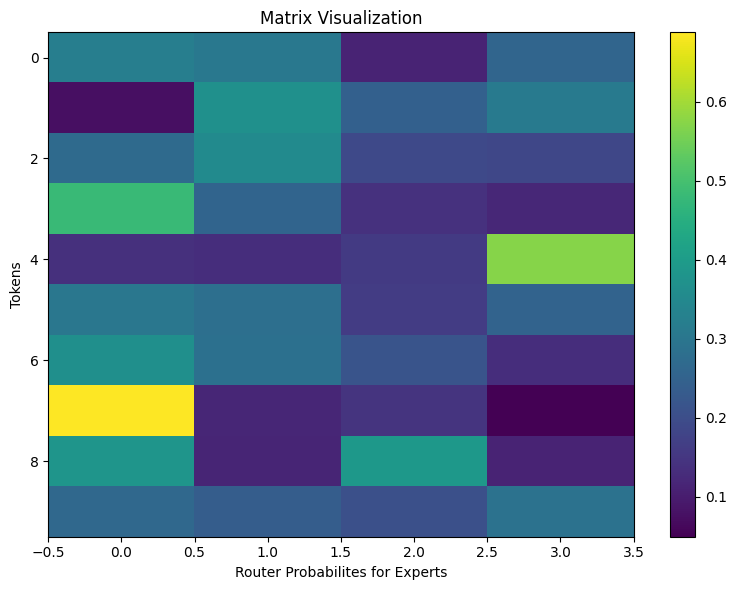

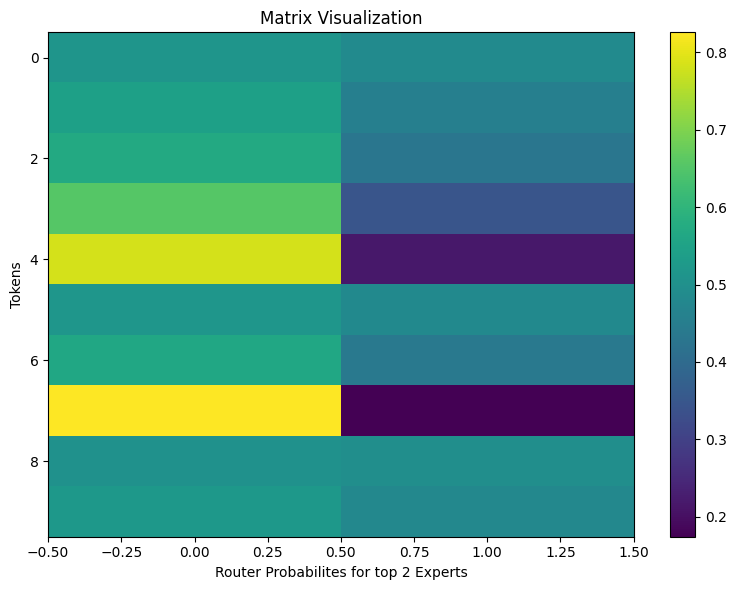

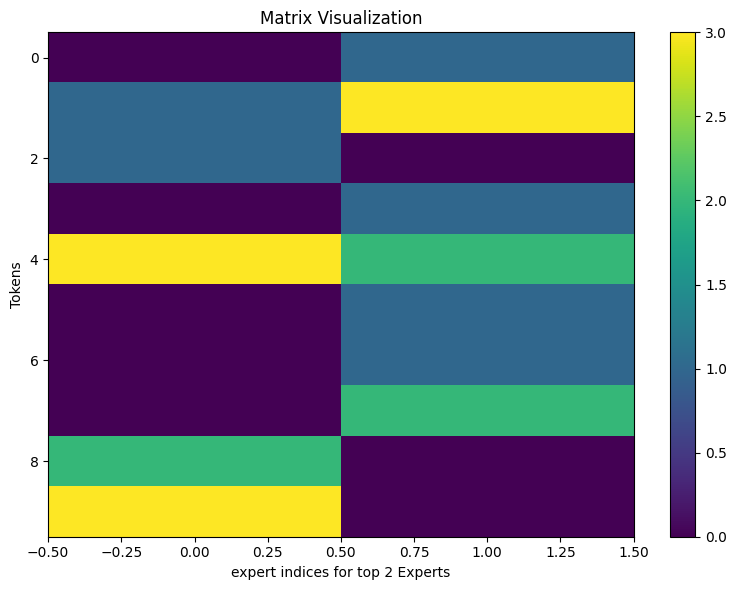

current expert index: 0


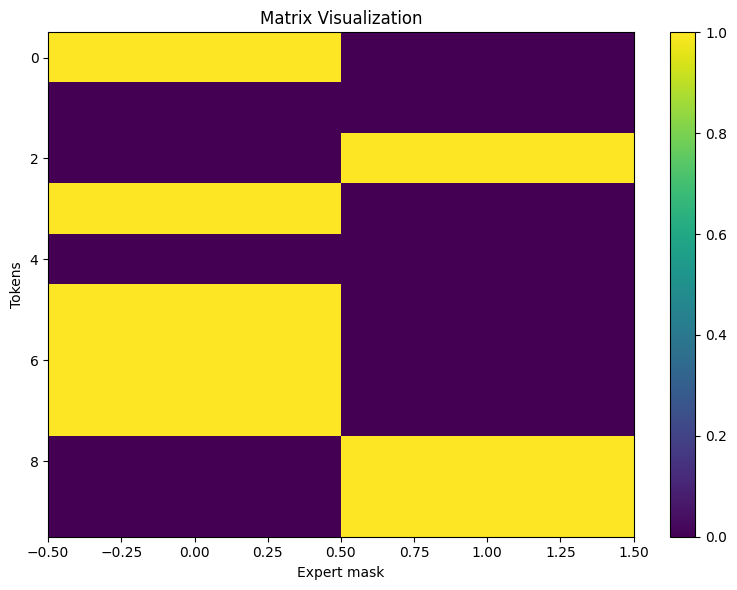

tensor([ True, False,  True,  True, False,  True,  True,  True,  True,  True])


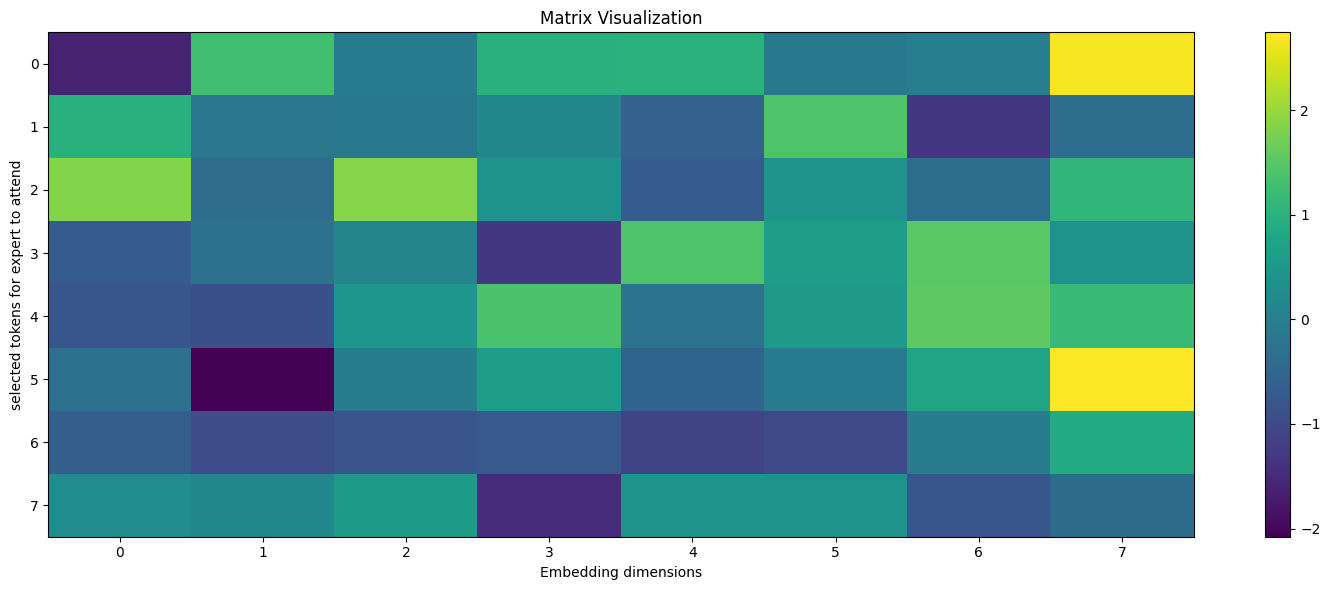

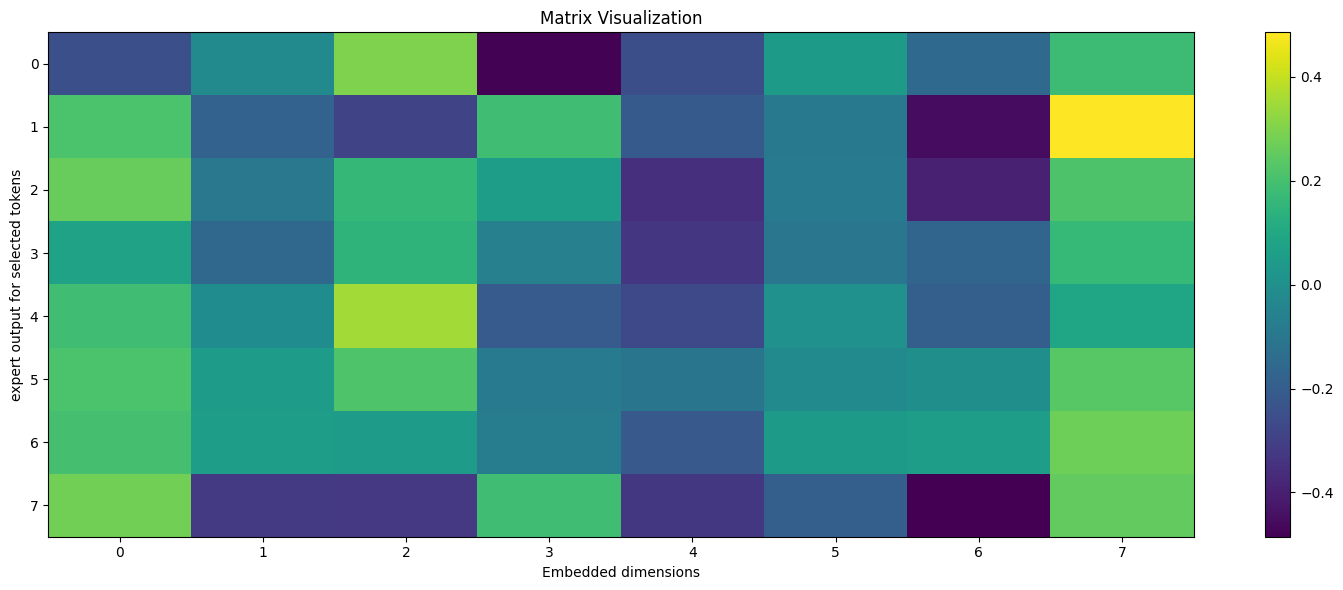

Weight Indices 
 0-- current expert is the 1st choice of the token
 1-- current exxpert is the 2nd choice of the token

tensor([0, 1, 0, 0, 0, 0, 1, 1])


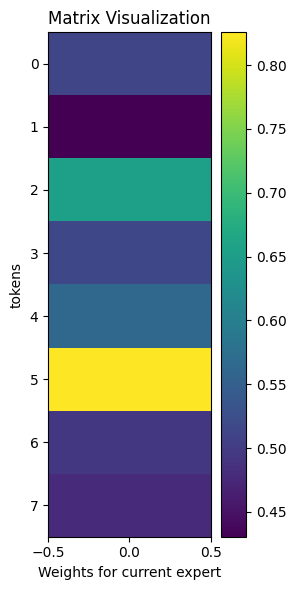

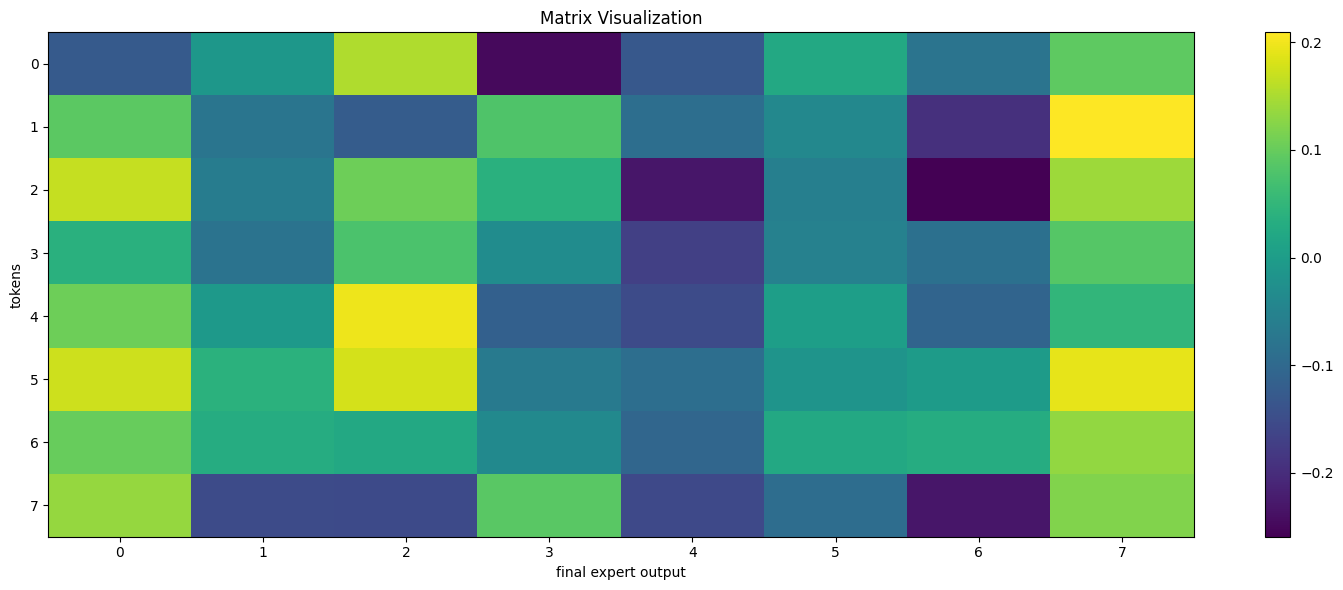

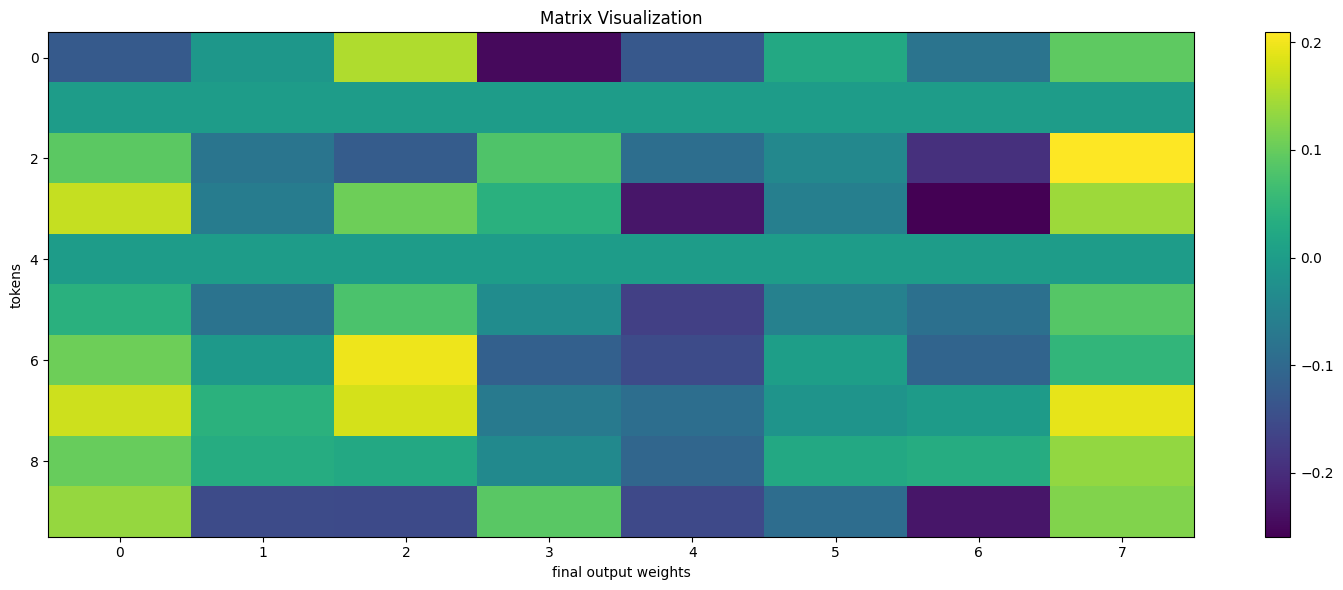

MoE output:
tensor([[[-0.1274, -0.0114,  0.1540, -0.2467, -0.1296,  0.0233, -0.0784,
           0.0934],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000],
         [ 0.0909, -0.0768, -0.1231,  0.0810, -0.0903, -0.0407, -0.1950,
           0.2092],
         [ 0.1689, -0.0634,  0.1051,  0.0373, -0.2308, -0.0565, -0.2594,
           0.1400],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000]],

        [[ 0.0382, -0.0816,  0.0765, -0.0318, -0.1709, -0.0530, -0.0868,
           0.0857],
         [ 0.1053, -0.0065,  0.1971, -0.1155, -0.1515,  0.0031, -0.1077,
           0.0497],
         [ 0.1734,  0.0403,  0.1789, -0.0669, -0.0892, -0.0163, -0.0020,
           0.1923],
         [ 0.0996,  0.0299,  0.0231, -0.0362, -0.1054,  0.0225,  0.0299,
           0.1341],
         [ 0.1342, -0.1532, -0.1549,  0.0899, -0.1566, -0.0915, -0.2319,
           0.1212]]], grad_fn=<ViewBackward0>)
Output shape: torch.Size([2, 

In [15]:
moe = MOELayer(
    in_dim=8,
    hidden_dim=16,
    num_experts=4,
    top_k=2
)

x = torch.randn(2, 5, 8)

output = moe(x)

print("MoE output:")
print(output)

print("Output shape:", output.shape)

In [18]:
def visualize_matrix(
    matrix,
    title="Matrix Visualization",
    x_label="Columns",
    y_label="Rows",
    width=15
):
    if isinstance(matrix, torch.Tensor):
        matrix = matrix.detach().cpu().numpy()
    else:
        matrix = np.asarray(matrix)

    fig, ax = plt.subplots(figsize=(width, 6))

    # No color representation
    ax.imshow(
        np.ones_like(matrix),
        cmap="gray",
        vmin=0,
        vmax=1,
        aspect="auto"
    )

    # Display actual numerical values
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j, i,
                f"{matrix[i, j]:.3f}" if matrix.dtype.kind in "fc"
                else str(matrix[i, j]),
                ha="center",
                va="center",
                color="black",
                fontsize=10
            )

    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    ax.set_xticks(np.arange(matrix.shape[1]))
    ax.set_yticks(np.arange(matrix.shape[0]))

    ax.set_xticks(np.arange(-0.5, matrix.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matrix.shape[0], 1), minor=True)

    ax.grid(which="minor", color="black", linestyle="-", linewidth=0.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    plt.tight_layout()
    plt.show()

Batch size : 2
 Sequence length : 5
 Embedding dimensions : 8

Flatten Dimensions : torch.Size([10, 8])

Router Output Shape : torch.Size([10, 4])



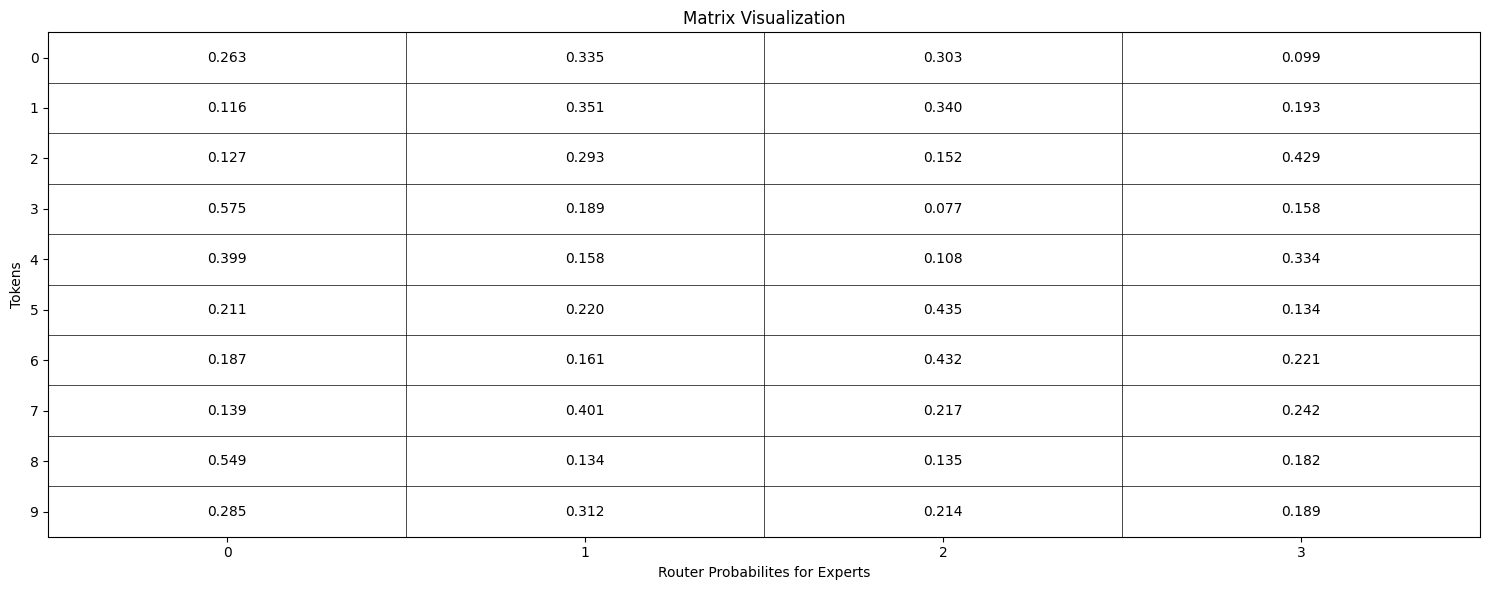

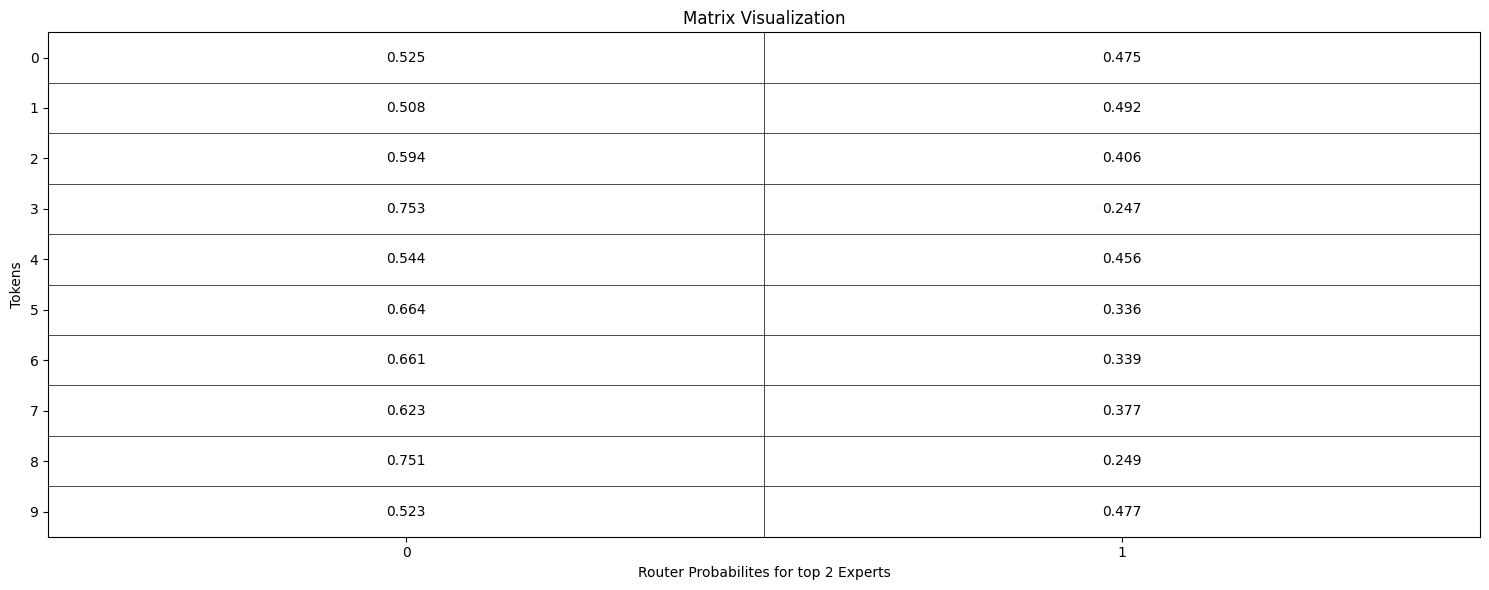

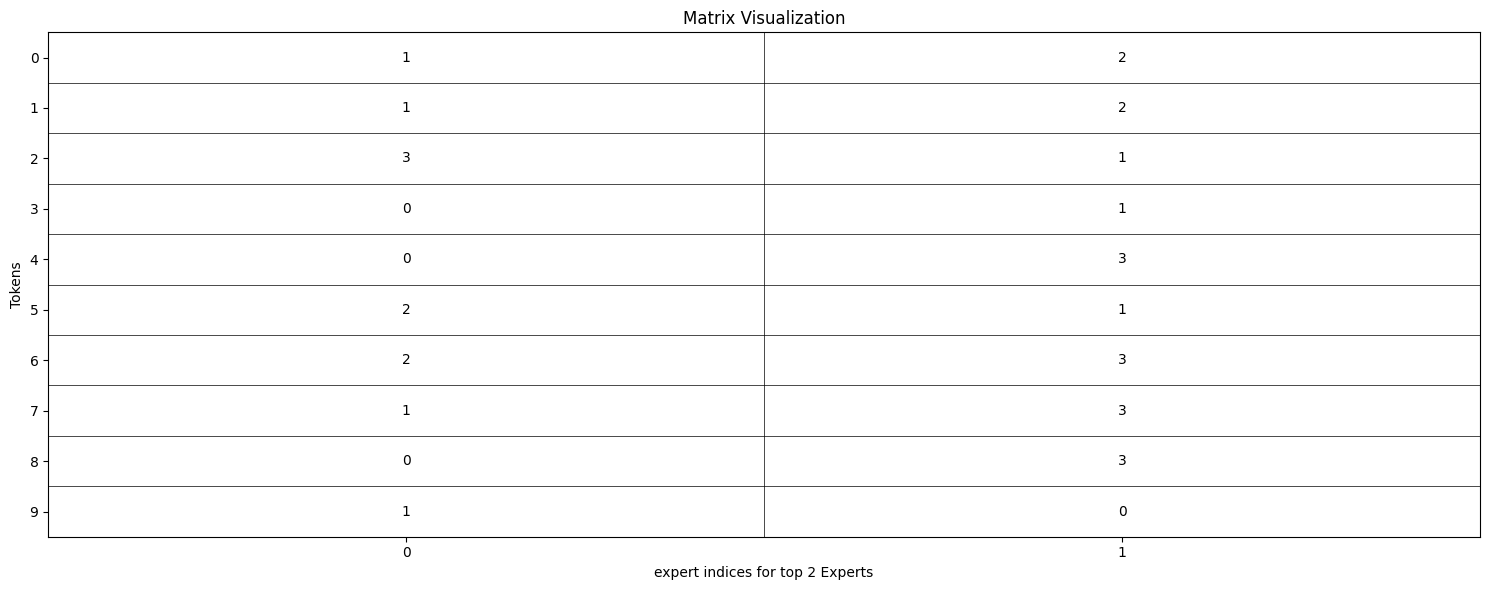

current expert index: 0


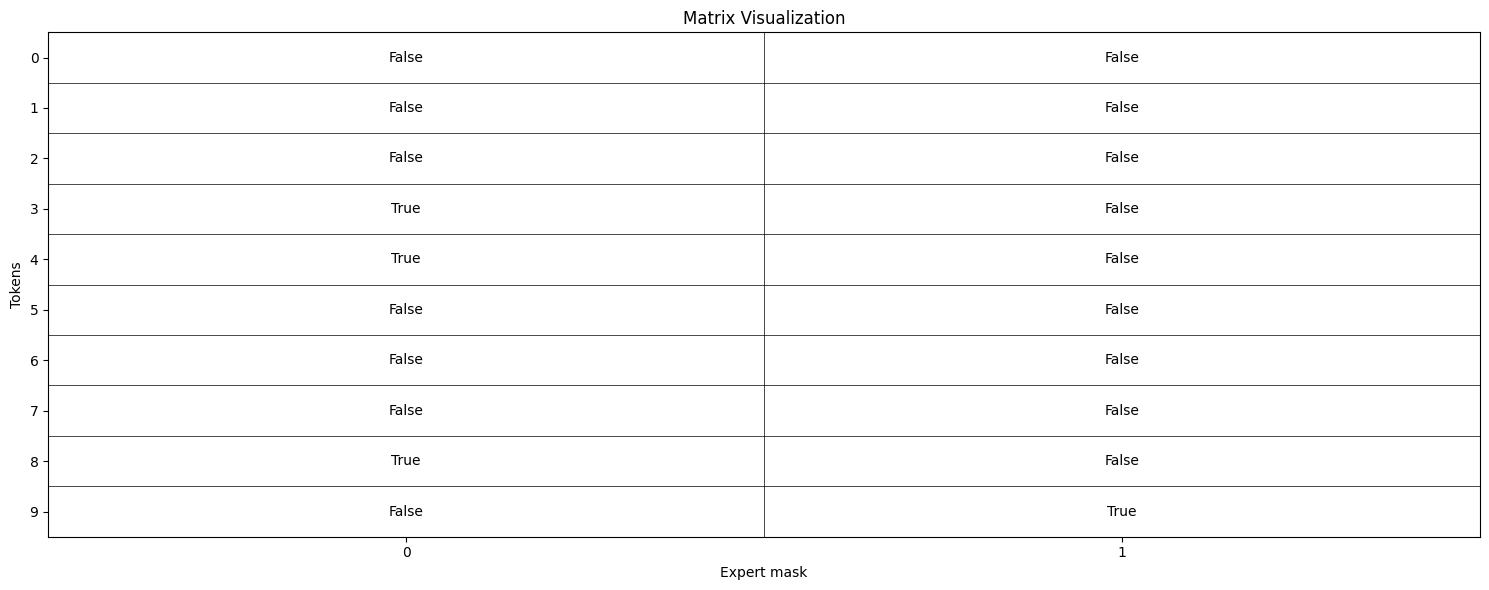

tensor([False, False, False,  True,  True, False, False, False,  True,  True])


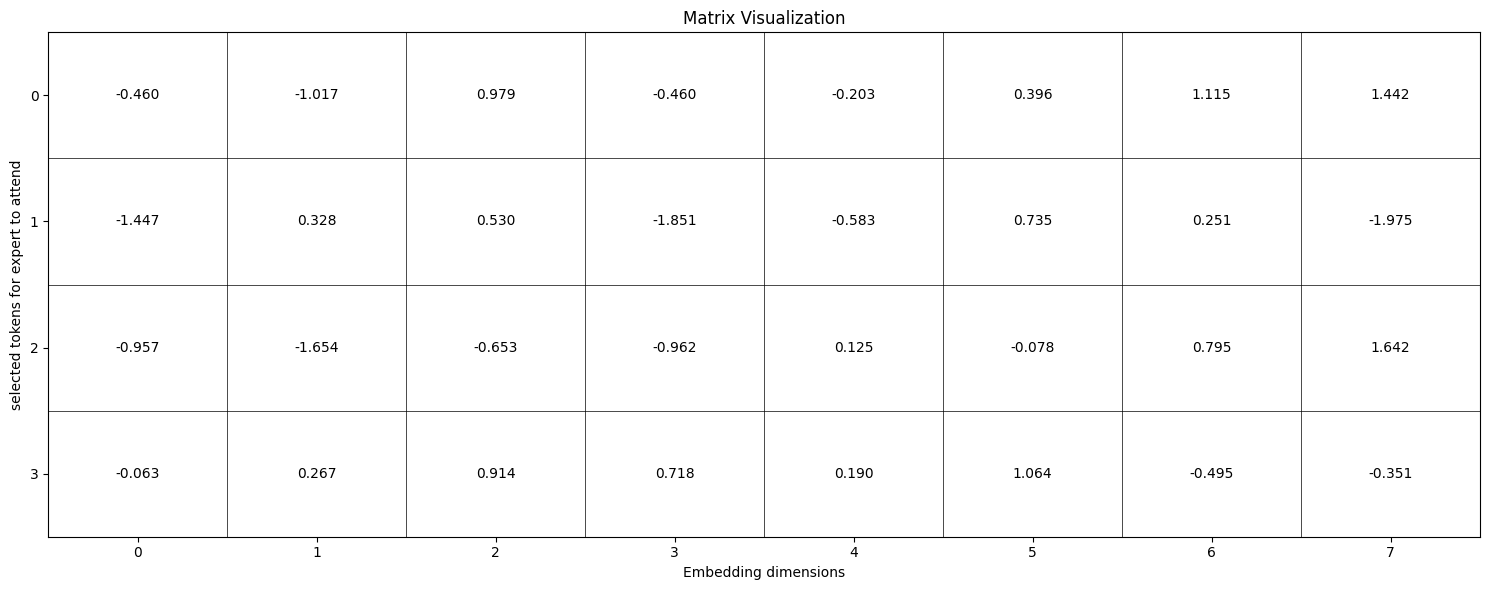

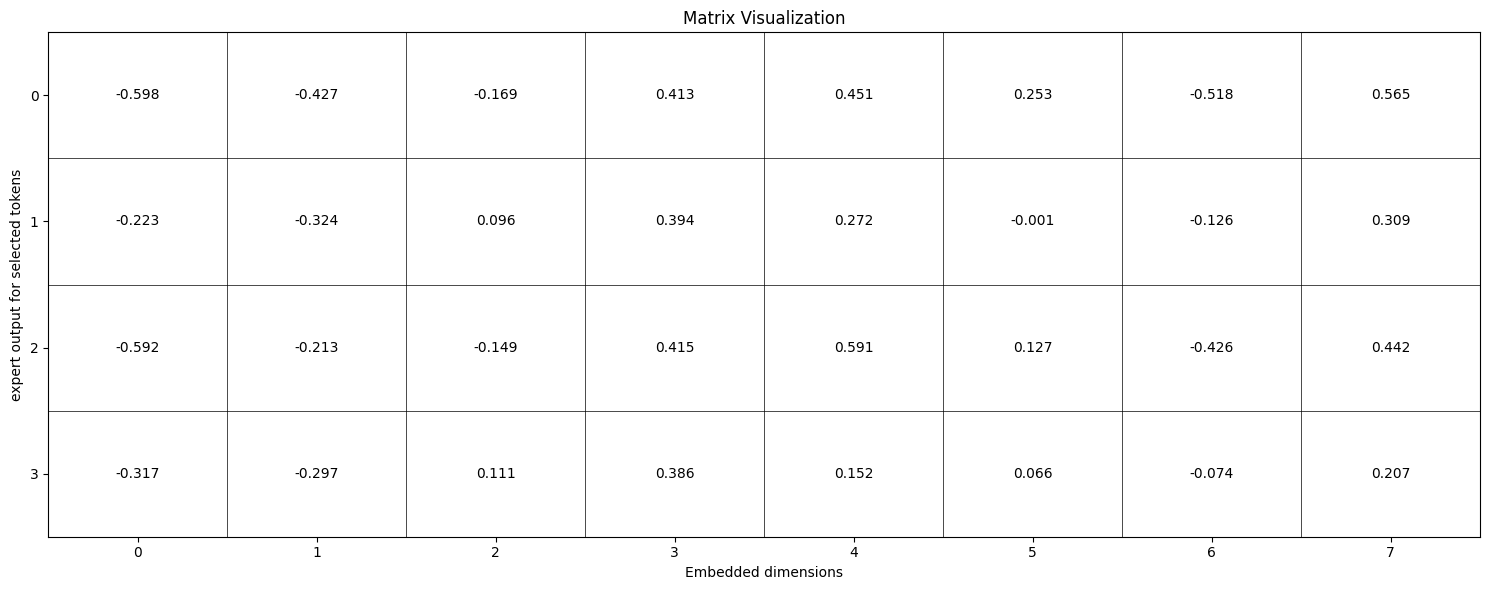

Weight Indices 
 0-- current expert is the 1st choice of the token
 1-- current exxpert is the 2nd choice of the token

tensor([0, 0, 0, 1])


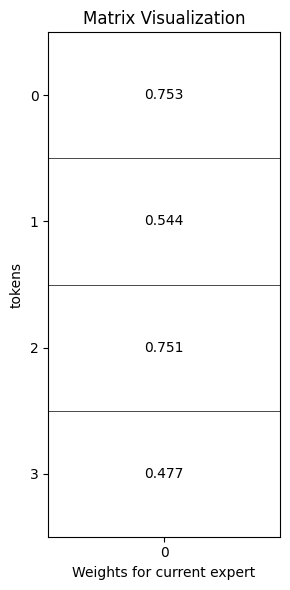

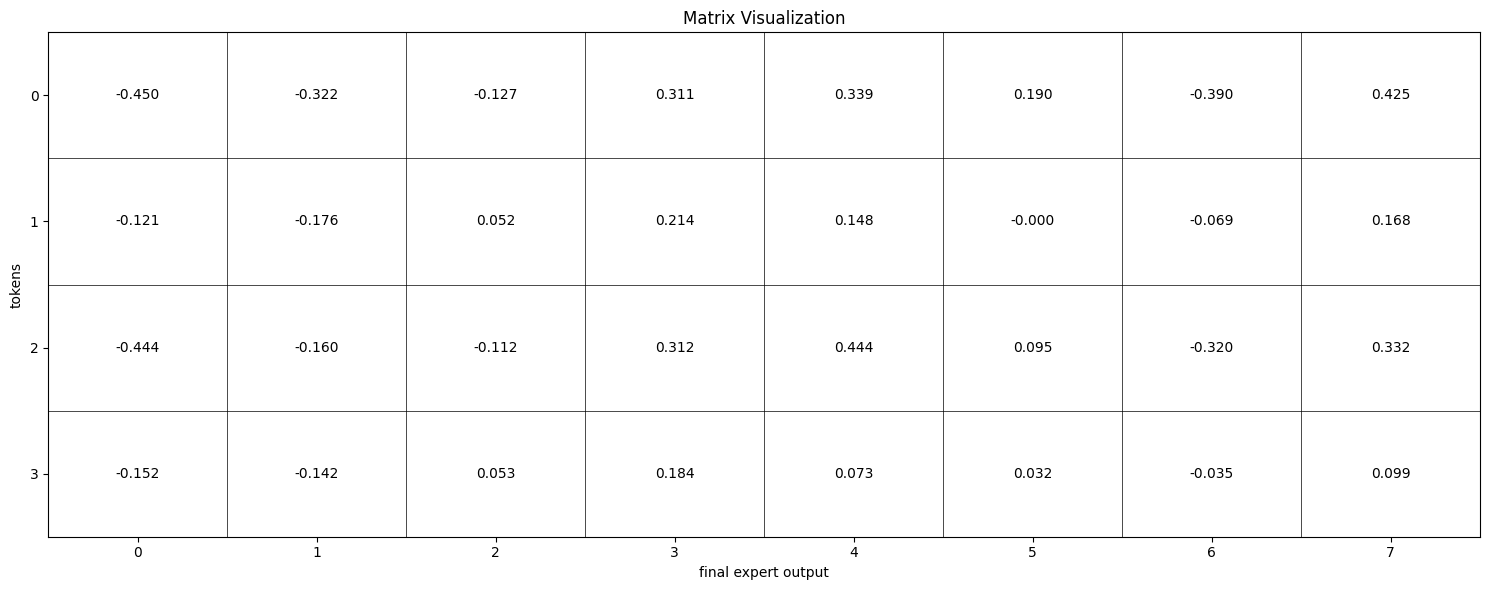

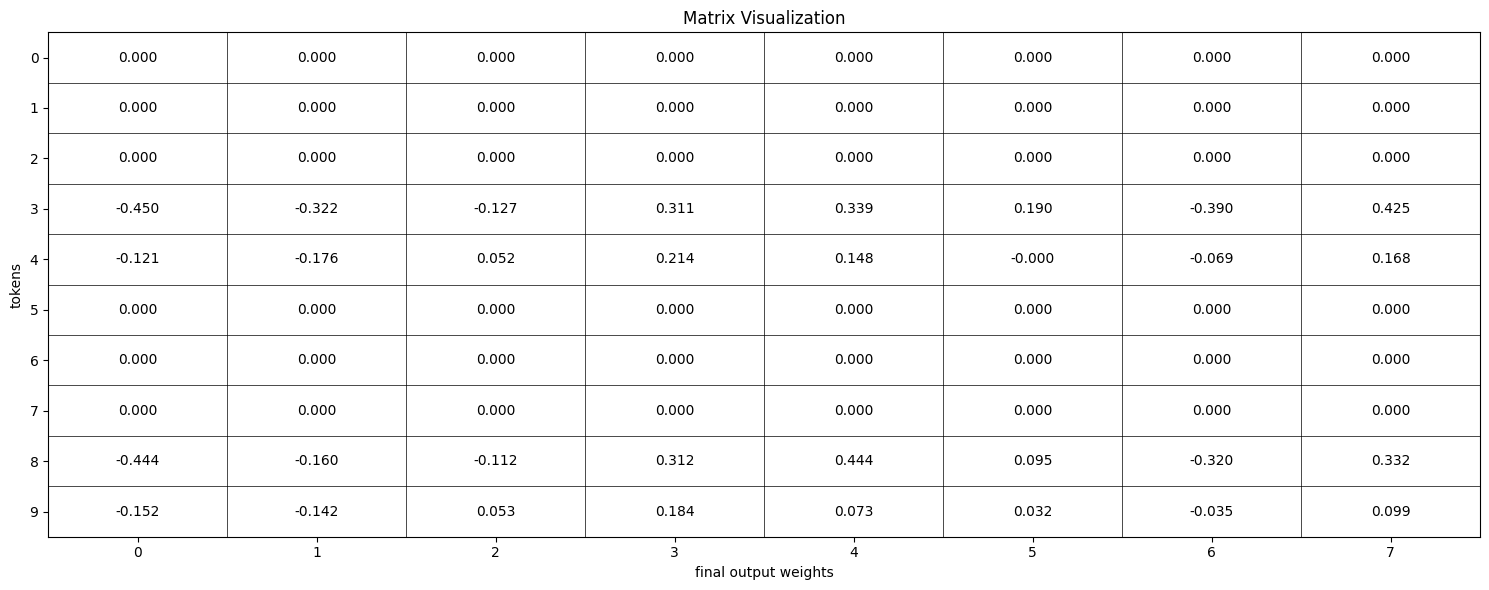

MoE output:
tensor([[[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  0.0000e+00,  0.0000e+00],
         [-4.4965e-01, -3.2166e-01, -1.2686e-01,  3.1105e-01,  3.3925e-01,
           1.9005e-01, -3.9001e-01,  4.2538e-01],
         [-1.2124e-01, -1.7634e-01,  5.2231e-02,  2.1449e-01,  1.4775e-01,
          -4.0743e-04, -6.8743e-02,  1.6829e-01]],

        [[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  0.0000e+00, 

In [19]:
moe = MOELayer(
    in_dim=8,
    hidden_dim=16,
    num_experts=4,
    top_k=2
)

x = torch.randn(2, 5, 8)

output = moe(x)

print("MoE output:")
print(output)

print("Output shape:", output.shape)